In [1]:
import sys
from pathlib import Path
import importlib

sys.path.insert(0, str(Path.cwd().parent))

import activation
import layers
import data_loader
import network
import losses

activation = importlib.reload(activation)
layers = importlib.reload(layers)
data_loader = importlib.reload(data_loader)
network = importlib.reload(network)

dl = data_loader
nw = network
from activation import ReLu, Softmax

load data

In [2]:
import idx2numpy
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# X_train = idx2numpy.convert_from_file("../../../dataset/archive/train-images-idx3-ubyte/train-images-idx3-ubyte")
# X_train = X_train = X_train[:, np.newaxis, :, :]
# X_train = X_train.astype(np.float64) / 255.0
# y_train = idx2numpy.convert_from_file("../../../dataset/archive/train-labels-idx1-ubyte/train-labels-idx1-ubyte")
# num_classes = 10
# y_train = np.eye(num_classes)[y_train]
# # (60000, 10)
# print("Training Images Shape :", X_train.shape)
# print("Training Labels Shape :", y_train.shape)
# print(X_train.dtype)

In [4]:
dataset = dl.build_dataset(size=64, transpose=True)
print(f"Indexed images: {len(dataset)}")

Indexed images: 42000


In [5]:
from sklearn.model_selection import train_test_split

indices = np.arange(len(dataset))
train_val_indices, test_indices = train_test_split(
    indices, test_size=0.15, random_state=42, stratify=dataset.labels
)

val_size_relative = 0.15 / (1.0 - 0.15)
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=val_size_relative,
    random_state=42,
    stratify=dataset.labels[train_val_indices],
)

train_dataset = dataset.subset(train_indices)
val_dataset = dataset.subset(val_indices)
test_dataset = dataset.subset(test_indices)

print(f"Indexed dataset size: {len(dataset)}")
print(f"Training set size: {len(train_dataset)}")
print(f"Validation set size: {len(val_dataset)}")
print(f"Test set size: {len(test_dataset)}")

Indexed dataset size: 42000
Training set size: 29400
Validation set size: 6300
Test set size: 6300


In [6]:
print(f"Input shape: (3, 64, 64)")
print(f"Training samples: {len(train_dataset)}")

Input shape: (3, 64, 64)
Training samples: 29400


In [7]:
model = nw.Network()

model.add_layer(layers.Convolutional(input_shape=(3, 64, 64), kernel_size=3, layer_size=16))
model.add_layer(layers.Convolutional(input_shape=(16, 62, 62), kernel_size=3, layer_size=16))
model.add_layer(layers.Flatten())
model.add_layer(layers.Dense((16 * 60 * 60, 128), 128, ReLu))
model.add_layer(layers.Dense((128, 1), 64, ReLu))
model.add_layer(layers.Dense((64, 1), 28, Softmax))

training

In [ ]:
history = model.train(
    loss=losses.categorical_cross_entropy,
    x_train=train_dataset,
    X_val=val_dataset,
    epochs=25,
    learning_rate=0.01,
    batch_size=32,
    shuffle=True,
    profile=True,
    verbose=True,
)

Batch 919: loss=3.2692
Epoch 1/25: train_accuracy=0.199, val_accuracy=0.339
Timing: load=376.139s, forward=180.414s, backward=2246.386s, update=110.169s, epoch=3058.081s, batch=3.328s
Batch 919: loss=3.1118
Epoch 2/25: train_accuracy=0.461, val_accuracy=0.569
Timing: load=395.965s, forward=189.069s, backward=2009.680s, update=159.196s, epoch=2857.872s, batch=3.110s
Batch 919: loss=2.9741
Epoch 3/25: train_accuracy=0.652, val_accuracy=0.693
Timing: load=369.012s, forward=168.881s, backward=1492.474s, update=90.778s, epoch=2243.250s, batch=2.441s
Batch 919: loss=2.9781
Epoch 4/25: train_accuracy=0.766, val_accuracy=0.787
Timing: load=401.802s, forward=169.166s, backward=1431.457s, update=88.277s, epoch=2222.549s, batch=2.418s
Batch 919: loss=2.7983
Epoch 5/25: train_accuracy=0.839, val_accuracy=0.843
Timing: load=401.527s, forward=168.174s, backward=1510.042s, update=89.323s, epoch=2274.560s, batch=2.475s
Batch 919: loss=2.7357
Epoch 6/25: train_accuracy=0.883, val_accuracy=0.870
Timing:

Saved training plots: p:\Academics\Semester 6\CSC03P3 AI Project\Project\Real-Time-Sign-Language-Recognition-and-Translation\ml\src\cnn\training_performance.png


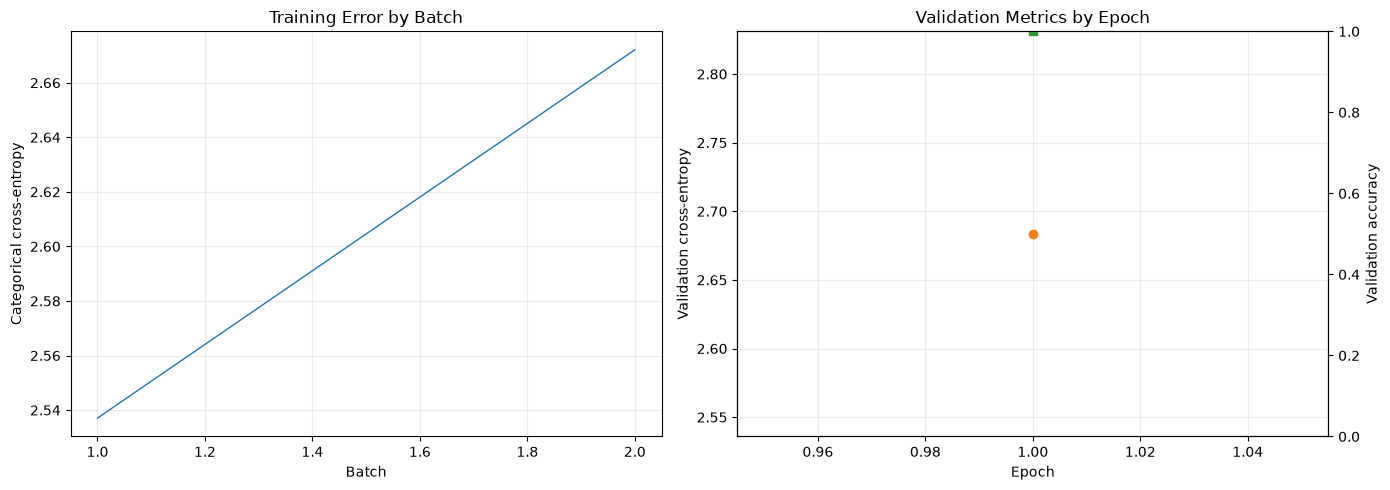

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

batch_numbers = np.arange(1, len(history["batch_loss"]) + 1)
axes[0].plot(batch_numbers, history["batch_loss"], color = "tab:blue", linewidth=1)
axes[0].set_title("Training Error by Batch")
axes[0].set_xlabel("Batch")
axes[0].set_ylabel("Categorical cross-entropy")
axes[0].grid(alpha=0.25)

axes[1].plot(history["epoch"], history["val_loss"], marker="o", color="tab:orange", label="Validation loss")
axes[1].set_title("Validation Metrics by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation cross-entropy")
axes[1].grid(alpha=0.25)

accuracy_axis = axes[1].twinx()
accuracy_axis.plot(history["epoch"], history["val_accuracy"], marker="s", color="tab:green", label="Validation accuracy")
accuracy_axis.set_ylabel("Validation accuracy")
accuracy_axis.set_ylim(0.0, 1.0)

fig.tight_layout()
plot_path = Path.cwd() / "training_performance.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
print(f"Saved training plots: {plot_path}")
plt.show()

In [ ]:
import pickle
from pathlib import Path

checkpoint_path = Path(network.__file__).resolve().parent / "sign_language_cnn_25_epochs.pkl"
with checkpoint_path.open("wb") as checkpoint_file:
    pickle.dump(model, checkpoint_file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"Saved trained CNN checkpoint: {checkpoint_path}")